# Thực Hành 1: Phân Loại Thời Trang Fashion-MNIST với PyTorch
## Báo Cáo Khám Phá Hình Học Dữ Liệu & Khảo Sát Thống Kê (EDA)

Notebook này thiết lập nền tảng khoa học dữ liệu cho bài toán phân loại trang phục Fashion-MNIST bằng PyTorch. Nội dung triển khai bao quát toàn bộ từ đặc tả bài toán (Define), thu nạp và quản trị dữ liệu bất biến (Data Collection & Governance), kiểm toán chất lượng 6 chiều (Data Quality Auditing), phân chia dữ liệu thực nghiệm (Dataset Splitting), cho đến khảo sát hình học dữ liệu toàn diện theo mô hình 3 Thấu Kính (The Three Lenses of EDA).

Mọi thiết kế bám sát kim chỉ nam tại [`docs/REPORT.md`](docs/REPORT.md) và tài liệu phương pháp luận [`docs/reference/ML_PIPELINE.md`](../../../docs/reference/ML_PIPELINE.md) (mục 2 đến 6). Theo đúng phạm vi kỹ thuật của giai đoạn đầu, notebook này kết luận sau khi hoàn thành EDA và không thực hiện chuỗi tiền xử lý dữ liệu (Data Processing).

## Bảng Lộ Trình Thực Thi & Liên Kết Tài Liệu Kỹ Thuật

| Step | Description | What it does | Import path |
| :---: | :--- | :--- | :---: |
| `1` | Environment & Seed Setup | Thiết lập cấu hình thiết bị động, seed ngẫu nhiên 248 và console giám sát | [`src/config.py`](../../../src/config.py) |
| `2` | Define Context & Problem | Bản đặc tả mục tiêu, ràng buộc công bằng thí nghiệm, baselines và metrics | — |
| `3` | Immutable Raw Ingestion | Tải Fashion-MNIST từ Zalando, lưu trữ bất biến và kiểm tra mã băm SHA-256 | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `4` | 6-Dimension Quality Audit | Kiểm toán 6 chiều chất lượng dữ liệu: Completeness, Accuracy, Consistency, Timeliness, Uniqueness, Validity | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `5` | Dataset Splitting | Phân chia tập dữ liệu: Train (55.000), Validation (5.000), Test (10.000) bảo toàn phân tầng và seed 248 | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `6` | EDA Lens 1: Global Topology | Khảo sát cấu trúc hình học tổng thể, tensor shapes, kiểu dữ liệu và dung lượng bộ nhớ | — |
| `7` | EDA Lens 2: Univariate Distribution | Đánh giá cân bằng lớp trên 3 tập và thống kê cường độ pixel (Histogram, KDE, Skewness, Kurtosis) | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `8` | EDA Lens 3: Visual & Separability | Thư viện ảnh mẫu 10 lớp, ảnh đại diện trung bình (Class Prototypes), tương quan và không gian PCA 2D | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `9` | Technical Decisions | Đúc kết phát hiện hình học để làm căn cứ thiết kế pipeline tiền xử lý và mô hình ở giai đoạn sau | — |

---
### Liên Kết Nhanh Tài Liệu & Báo Cáo Kỹ Thuật
- 📄 Báo Cáo Kỹ Thuật Toàn Diện: [`docs/REPORT.md`](docs/REPORT.md)
- 🌐 Báo Cáo Trực Quan HTML: [`docs/REPORT.html`](docs/REPORT.html)
- 📋 Đặc Tả Yêu Cầu Kỹ Thuật Bài Thực Hành: [`docs/QUESTION.md`](docs/QUESTION.md)
- 📖 Phương Pháp Luận Pipeline Chuẩn Hóa: [`docs/reference/ML_PIPELINE.md`](../../../docs/reference/ML_PIPELINE.md)
- 🏠 Tài Liệu Hướng Dẫn Dự Án: [`README.md`](../../../README.md)


## 1. Thiết Lập Môi Trường Thực Thi & Khóa Ngẫu Nhiên Tái Lập (Setup)

Khởi tạo cấu hình môi trường tính toán, đồng bộ hóa hạt giống ngẫu nhiên (`seed = 248`) trên toàn bộ các thư viện Python, NumPy và PyTorch để bảo đảm tính tái lập thực nghiệm 100%.

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.datasets import FashionMNIST
from torch.utils.data import Subset

from src import config, consoles
from src.vibe_scripts import eda_helpers


# Hiển thị cấu hình phần cứng và siêu tham số hệ thống
consoles.creation()

                          Configuration                           
┌───────────────┬────────────────────────────────────────────────┐
│ Root          │ D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH │
│ Version       │ 2.15.0+cu132                                   │
│ Device        │ cuda                                           │
│ GPU           │ NVIDIA GeForce RTX 4060 Laptop GPU             │
│ VRAM          │ 8.6 GB                                         │
│ Seed          │ 248                                            │
│ Workers       │ 8                                              │
│ Batch size    │ 32                                             │
│ Learning rate │ 1e-05                                          │
│ Epoch         │ 30                                             │
└───────────────┴────────────────────────────────────────────────┘


## 2. Đặc Tả Bài Toán & Bối Cảnh Thực Nghiệm (Define Context & Problem)

Tuân thủ đặc tả kỹ thuật tại [`docs/REPORT.md`](docs/REPORT.md):

### 2.1. Bối cảnh (Define Context)
- **Tên bài toán:** So sánh hiệu năng CNN, MLP, Logistic trên bài toán phân loại Fashion-MNIST bằng PyTorch.
- **Bối cảnh thực hiện:** Bài thực hành học sâu (Deep Learning) chuyên sâu với thư viện PyTorch.
- **Mục tiêu chính (Target):**
  - *Mục tiêu cốt lõi:* Làm quen PyTorch, làm chủ quy trình xây dựng mô hình và khảo sát dữ liệu chuẩn mực.
  - *Mục tiêu bổ sung:* Hoàn thành đầy đủ các yêu cầu so sánh và phân tích kỹ thuật của đề bài.
- **Ràng buộc công bằng thí nghiệm (Constraints):**
  - Công bằng thí nghiệm: Sử dụng cùng optimizer, learning rate, batch size, số epoch và cùng seed ngẫu nhiên cho cả 3 mô hình.
  - Ràng buộc tham số: Mô hình MLP và CNN phải có số lượng tham số cùng bậc độ phức tạp để đánh giá khách quan.

### 2.2. Đặc tả Bài toán (Define Problem)
- **Dữ liệu đầu vào (Input):** Ảnh xám kích thước $28 \times 28$ điểm ảnh.
- **Đầu ra mong đợi (Output):** Dự đoán danh mục nhãn thuộc 10 lớp thời trang và báo cáo đánh giá định lượng.
- **Chỉ số đánh giá (Metrics):** Accuracy, số lượng tham số mô hình, số epoch hội tụ, ma trận nhầm lẫn (Confusion Matrix).
- **Mô hình cơ sở (Baseline):** Mô hình hồi quy Logistic (Logistic Regression).
- **Thực nghiệm mở rộng:** Đánh giá ảnh hưởng của việc cố định seed và kỹ thuật tăng cường dữ liệu (Data Augmentation) trên mô hình CNN.

## 3. Thu Nạp & Quản Trị Dữ Liệu Bất Biến (Data Collection & Governance - §2, §3)

Áp dụng nguyên tắc **Vùng Dữ Liệu Bất Biến (Immutable Raw Zone - §3.1)**:
- Dữ liệu thô tải từ Zalando Research qua `torchvision.datasets.FashionMNIST` được lưu trữ tại `data/FashionMNIST/raw/`.
- Toàn bộ các file nhị phân gốc là chỉ đọc (read-only), tuyệt đối không sửa đổi trực tiếp trên nguồn dữ liệu này.
- Tính toán mã băm mật mã học SHA-256 cho từng tệp để bảo đảm tính toàn vẹn nguồn gốc (Data Lineage & Provenance).

In [2]:
# Tải và khởi tạo dataset thô (dữ liệu pixel gốc 0-255)
raw_train = FashionMNIST(root=config.DATA_PATH, train=True, download=False)
raw_test  = FashionMNIST(root=config.DATA_PATH, train=False, download=False)

print(f"Số lượng mẫu Train thô : {len(raw_train):,}")
print(f"Số lượng mẫu Test thô  : {len(raw_test):,}")
print(f"Kích thước ảnh mẫu      : {raw_train.data[0].shape} (Chiều cao H x Chiều rộng W)")
print(f"Kiểu dữ liệu gốc        : {raw_train.data.dtype}")
print(f"Danh sách 10 nhãn lớp   : {eda_helpers.FASHION_CLASSES}")

# Xác thực mã băm SHA-256 bảo đảm tính bất biến của tệp thô
raw_dir = config.DATA_PATH / "FashionMNIST" / "raw"
print("\n--- XÁC THỰC DATA LINEAGE & CHECKSUM (SHA-256) ---")
for f in sorted(raw_dir.glob("*-ubyte*")):
    checksum = eda_helpers.calculate_file_sha256(f)
    print(f"{f.name:<30} : {checksum[:20]}...")

Số lượng mẫu Train thô : 60,000
Số lượng mẫu Test thô  : 10,000
Kích thước ảnh mẫu      : torch.Size([28, 28]) (Chiều cao H x Chiều rộng W)
Kiểu dữ liệu gốc        : torch.uint8
Danh sách 10 nhãn lớp   : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

--- XÁC THỰC DATA LINEAGE & CHECKSUM (SHA-256) ---
t10k-images-idx3-ubyte         : 5b4141f0afbad91edebe...
t10k-images-idx3-ubyte.gz      : 346e55b948d973a97e58...
t10k-labels-idx1-ubyte         : 0402a96d92fd26639571...
t10k-labels-idx1-ubyte.gz      : 67da17c76eaffca5446c...
train-images-idx3-ubyte        : c59f468a2f672dc81568...
train-images-idx3-ubyte.gz     : 3aede38d61863908ad78...
train-labels-idx1-ubyte        : bad3541b69d912435c50...
train-labels-idx1-ubyte.gz     : a04f17134ac03560a47e...


## 4. Kiểm Toán Chất Lượng Dữ Liệu 6 Chiều (Data Quality Auditing - §4, §5)

Trước khi thực hiện phân chia dữ liệu hay phân tích sâu, ta tiến hành kiểm toán 6 chiều chất lượng dữ liệu theo tiêu chuẩn CRISP-DM / KDD:
1. **Completeness (Đầy đủ):** Rà soát giá trị NaN, Null hoặc điểm ảnh bị thiếu.
2. **Accuracy (Chính xác):** Đảm bảo giá trị pixel nằm trong thang đo vật lý hợp lệ từ 0 đến 255.
3. **Consistency (Nhất quán):** Nhãn lớp thuộc tập định danh 10 danh mục từ 0 đến 9.
4. **Timeliness (Tính kịp thời):** Bộ chuẩn đối sánh tĩnh chuẩn mực từ Zalando Research.
5. **Uniqueness (Tính duy nhất):** Kiểm tra trùng lặp bản ghi và định danh.
6. **Validity (Tính hợp thức):** Cấu trúc hình học ảnh $28 \times 28$ điểm ảnh trên 1 kênh đơn sắc.

In [3]:
audit_results = eda_helpers.audit_six_dimensions(
    raw_train.data, raw_train.targets,
    raw_test.data, raw_test.targets
)

eda_helpers.print_audit_table(audit_results)

print(f"\nKết luận kiểm toán: Dữ liệu đạt tỷ lệ hoàn thiện {audit_results['completeness_pct']:.1f}% với 0 giá trị null.")
print("Đúng như ghi nhận tại REPORT.md: Bộ dữ liệu đã được làm sạch chuẩn mực, an toàn bỏ qua bước Data Cleaning.")

               Data Quality Audit (6 Dimensions - CRISP-DM / §4)               
┌──────────────┬────────────────────────────────┬──────────────────┬──────────┐
│ Dimension    │ Verification Check             │ Metric / Status  │ Assessm… │
├──────────────┼────────────────────────────────┼──────────────────┼──────────┤
│ 1.           │ Null / Missing value scan      │ Missing: 0       │ [PASS]   │
│ Completeness │ across tensors                 │ (100.0%)         │ Clean    │
│ 2. Accuracy  │ Physical pixel domain          │ Range: [0, 255]  │ [PASS]   │
│              │ conformity [0, 255]            │                  │ Valid    │
│ 3.           │ Target classes domain          │ 10 Classes (0-9) │ [PASS]   │
│ Consistency  │ integrity                      │                  │ Consist… │
│ 4.           │ Benchmark dataset currency &   │ Zalando Research │ [PASS]   │
│ Timeliness   │ immutability                   │ (Fixed)          │ Static   │
│ 5.           │ Entity deduplication & 

## 5. Phân Chia Dữ Liệu Thực Nghiệm Chuẩn Mực (Dataset Splitting)

Bám sát phân rã tại [`docs/REPORT.md`](docs/REPORT.md):
- **Tập Huấn luyện (Train):** 55.000 mẫu.
- **Tập Đánh giá Xác thực (Validation):** 5.000 mẫu.
- **Tập Kiểm thử Độc lập (Test):** 10.000 mẫu.

Phương pháp phân chia áp dụng **Stratified Split** với seed ngẫu nhiên cố định 248, đảm bảo tỷ lệ số lượng mẫu phân bổ cho mỗi lớp là hoàn toàn cân bằng giữa tập Train (5.500 mẫu/lớp) và Validation (500 mẫu/lớp).

In [4]:
# Phân tầng tập Train 60k thành 55k Train và 5k Validation
train_indices, val_indices = eda_helpers.stratified_split_indices(
    raw_train.targets.numpy(),
    train_size=55000,
    val_size=5000,
    seed=config.SEED
)

train_dataset = Subset(raw_train, train_indices)
val_dataset   = Subset(raw_train, val_indices)
test_dataset  = raw_test

print("PHÂN CHIA TẬP THỰC NGHIỆM THÀNH CÔNG:")
print(f"- Train Set      : {len(train_dataset):,} mẫu")
print(f"- Validation Set : {len(val_dataset):,} mẫu")
print(f"- Test Set       : {len(test_dataset):,} mẫu")
print(f"- Tổng cộng      : {len(train_dataset) + len(val_dataset) + len(test_dataset):,} mẫu")

PHÂN CHIA TẬP THỰC NGHIỆM THÀNH CÔNG:
- Train Set      : 55,000 mẫu
- Validation Set : 5,000 mẫu
- Test Set       : 10,000 mẫu
- Tổng cộng      : 70,000 mẫu


## 6. Khảo Sát Khám Phá Hình Học Dữ Liệu (Exploratory Data Analysis - EDA)

Thực hiện theo khung phương pháp luận **Three Lenses of EDA** quy định tại [`docs/reference/ML_PIPELINE.md`](../../../docs/reference/ML_PIPELINE.md) (§6):
- **Lens 1: Cấu trúc Hình học Tổng thể (Global Topology):** Kích thước ma trận, kiểu dữ liệu, mức tiêu thụ bộ nhớ, rà soát giá trị khuyết.
- **Lens 2: Phân bố Đơn biến (Univariate Distributions):** Cân bằng tần suất các lớp, thống kê mô tả cường độ điểm ảnh, độ lệch (Skewness), độ nhọn (Kurtosis), tỷ lệ mật độ nền.
- **Lens 3: Tương tác Đa biến & Khả năng Phân tách Lớp (Multivariate & Class Separability):** Trực quan hóa mẫu ảnh, ảnh đại diện trung bình (Class Prototypes), tương quan không gian giữa các lớp và biểu diễn giảm chiều PCA 2D.

### 6.1. Lens 1: Cấu Trúc Hình Học Tổng Thể (Global Topology)

Khảo sát các đặc tính không gian và cấu trúc lưu trữ của tensor dữ liệu ảnh gốc.

In [5]:
train_data_tensor = raw_train.data
test_data_tensor  = raw_test.data

# Tính toán dung lượng bộ nhớ (RAM footprint)
train_memory_mb = (train_data_tensor.element_size() * train_data_tensor.nelement()) / (1024 ** 2)
test_memory_mb  = (test_data_tensor.element_size() * test_data_tensor.nelement()) / (1024 ** 2)

print("--- LENS 1: GLOBAL TOPOLOGY AUDIT ---")
print(f"- Train Tensor Shape     : {train_data_tensor.shape} (N_samples, H, W)")
print(f"- Test Tensor Shape      : {test_data_tensor.shape} (N_samples, H, W)")
print(f"- Storage Data Type      : {train_data_tensor.dtype}")
print(f"- Train Memory Footprint : {train_memory_mb:.2f} MB")
print(f"- Test Memory Footprint  : {test_memory_mb:.2f} MB")
print(f"- Tổng số điểm ảnh/ảnh   : {28 * 28} pixels (784 chiều không gian)")
print(f"- Tổng số chiều quan sát : {train_data_tensor.ndim} chiều")

--- LENS 1: GLOBAL TOPOLOGY AUDIT ---
- Train Tensor Shape     : torch.Size([60000, 28, 28]) (N_samples, H, W)
- Test Tensor Shape      : torch.Size([10000, 28, 28]) (N_samples, H, W)
- Storage Data Type      : torch.uint8
- Train Memory Footprint : 44.86 MB
- Test Memory Footprint  : 7.48 MB
- Tổng số điểm ảnh/ảnh   : 784 pixels (784 chiều không gian)
- Tổng số chiều quan sát : 3 chiều


### 6.2. Lens 2: Phân Bố Đơn Biến (Univariate Distributions)

Đo lường độ cân bằng phân bố tần suất lớp trên các tập và phân tích thống kê mô tả cường độ điểm ảnh.

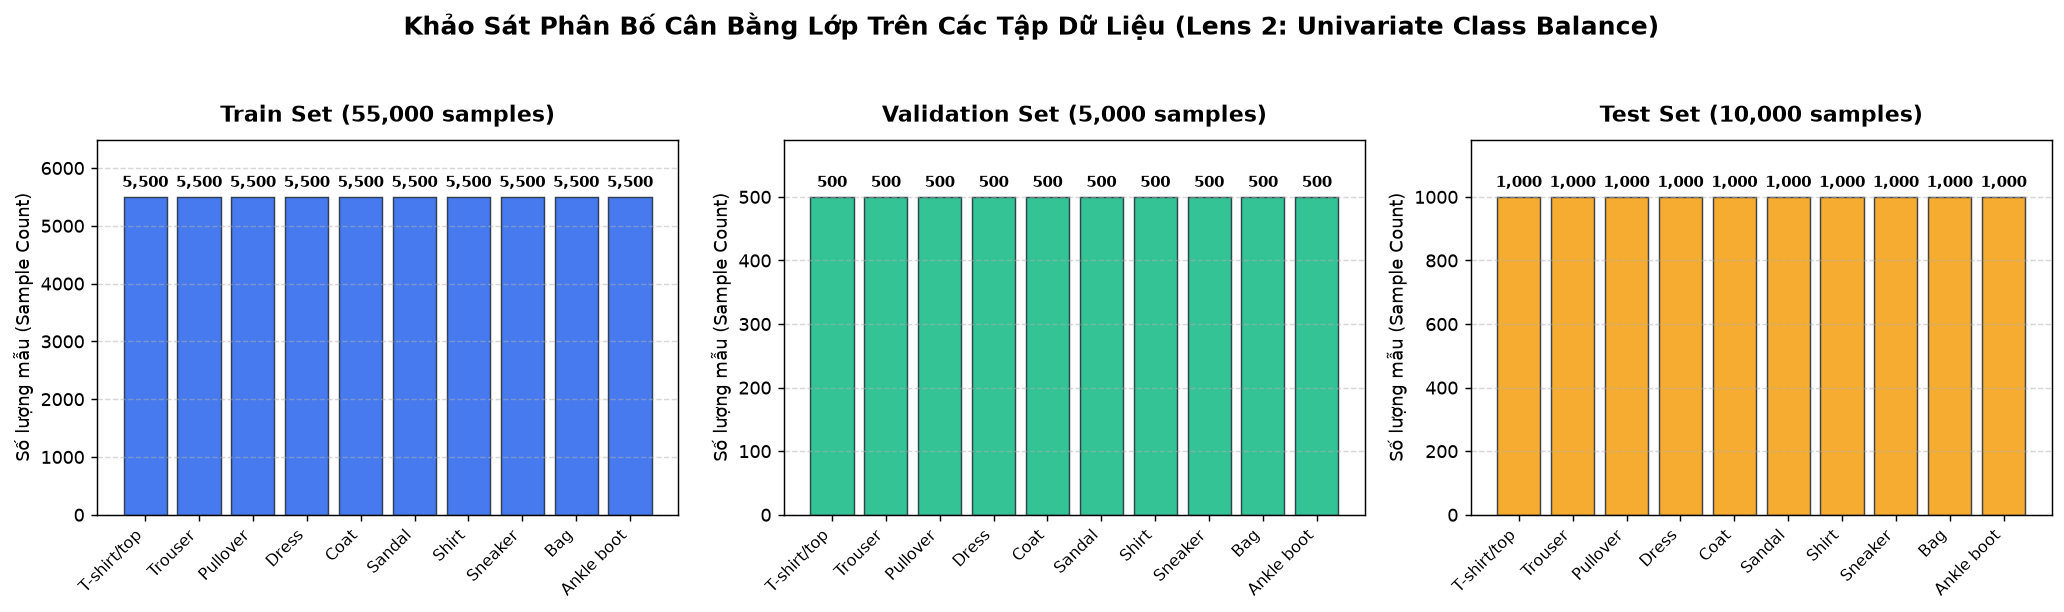

In [6]:
# Thu thập nhãn của 3 tập thực nghiệm
train_targets_arr = raw_train.targets[train_indices].numpy()
val_targets_arr   = raw_train.targets[val_indices].numpy()
test_targets_arr  = raw_test.targets.numpy()

# Trực quan hóa đối chiếu phân bố lớp
fig_balance = eda_helpers.plot_class_balance(train_targets_arr, val_targets_arr, test_targets_arr)
plt.show()

--- LENS 2: UNIVARIATE PIXEL DISTRIBUTION STATISTICS ---
- Giá trị Trung bình (Mean)  : 72.94 (trên thang 0-255) -> Chuẩn hóa: 0.2860
- Độ lệch chuẩn (Std)        : 90.02 (trên thang 0-255) -> Chuẩn hóa: 0.3530
- Trung vị (Median)          : 0.0
- Hệ số Bất đối xứng (Skew)  : 0.695 (Lệch phải mạnh do đa số là điểm ảnh nền)
- Độ nhọn (Kurtosis)         : -1.190
- Tỷ lệ Điểm ảnh Nền (= 0)   : 50.21%


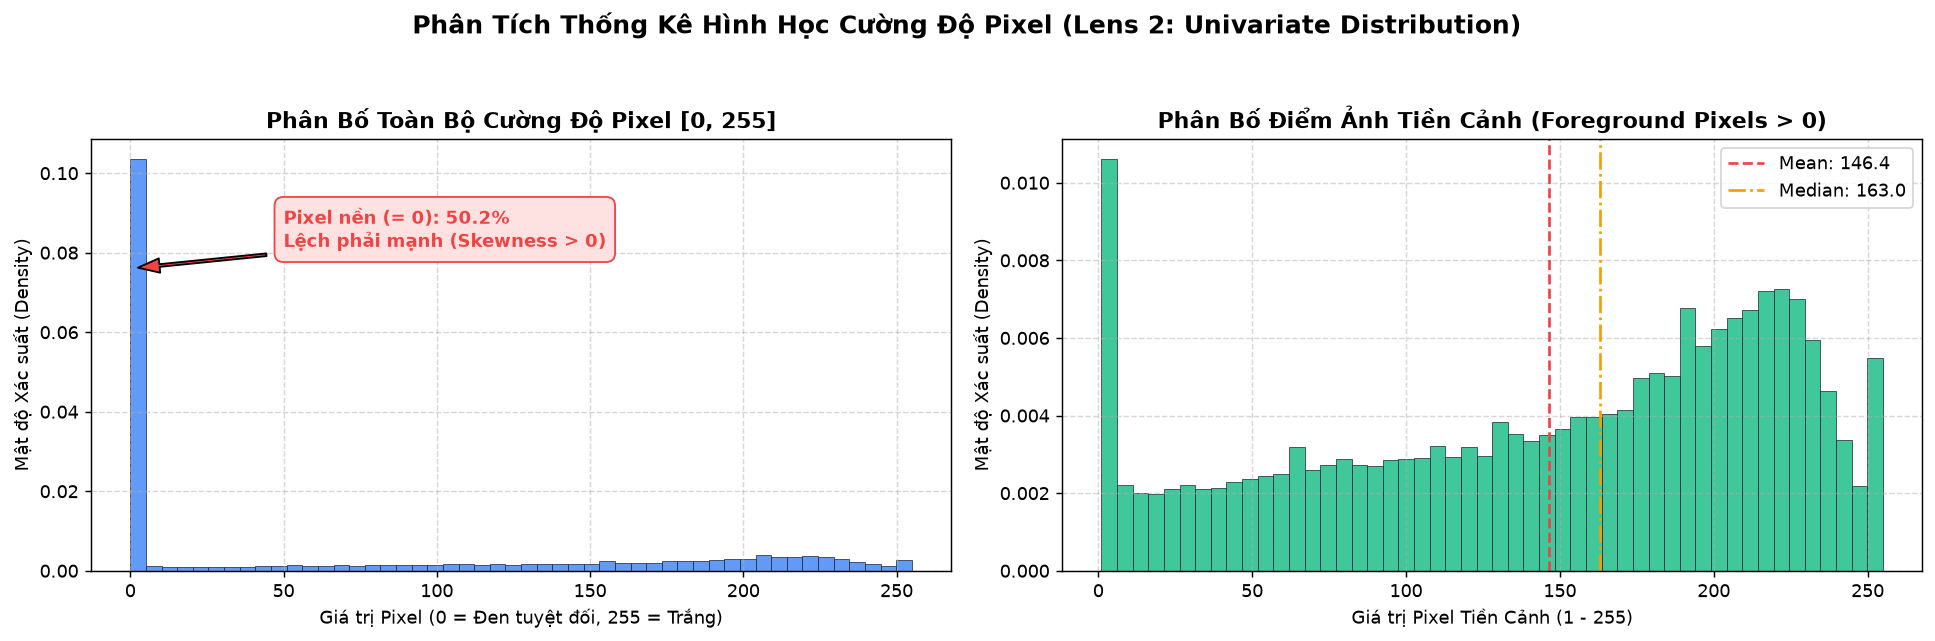

In [7]:
# Tính toán thống kê mô tả cường độ pixel trên tập Train
pixel_stats = eda_helpers.compute_pixel_statistics(raw_train.data)

print("--- LENS 2: UNIVARIATE PIXEL DISTRIBUTION STATISTICS ---")
print(f"- Giá trị Trung bình (Mean)  : {pixel_stats['mean']:.2f} (trên thang 0-255) -> Chuẩn hóa: {pixel_stats['mean']/255:.4f}")
print(f"- Độ lệch chuẩn (Std)        : {pixel_stats['std']:.2f} (trên thang 0-255) -> Chuẩn hóa: {pixel_stats['std']/255:.4f}")
print(f"- Trung vị (Median)          : {pixel_stats['median']:.1f}")
print(f"- Hệ số Bất đối xứng (Skew)  : {pixel_stats['skewness']:.3f} (Lệch phải mạnh do đa số là điểm ảnh nền)")
print(f"- Độ nhọn (Kurtosis)         : {pixel_stats['kurtosis']:.3f}")
print(f"- Tỷ lệ Điểm ảnh Nền (= 0)   : {pixel_stats['sparsity_zero_pct']:.2f}%")

# Trực quan hóa biểu đồ Histogram và mật độ xác suất điểm ảnh
fig_pixel_dist = eda_helpers.plot_pixel_distribution_analysis(raw_train.data.numpy())
plt.show()

### 6.3. Lens 3: Tương Tác Đa Biến & Khả Năng Phân Tách Lớp (Multivariate & Visual Separability)

Khảo sát các đặc trưng hình thái học không gian, ảnh trung bình nguyên mẫu (Class Prototypes), ma trận tương quan giữa các danh mục và khả năng phân tách cụm trong không gian giảm chiều PCA 2D.

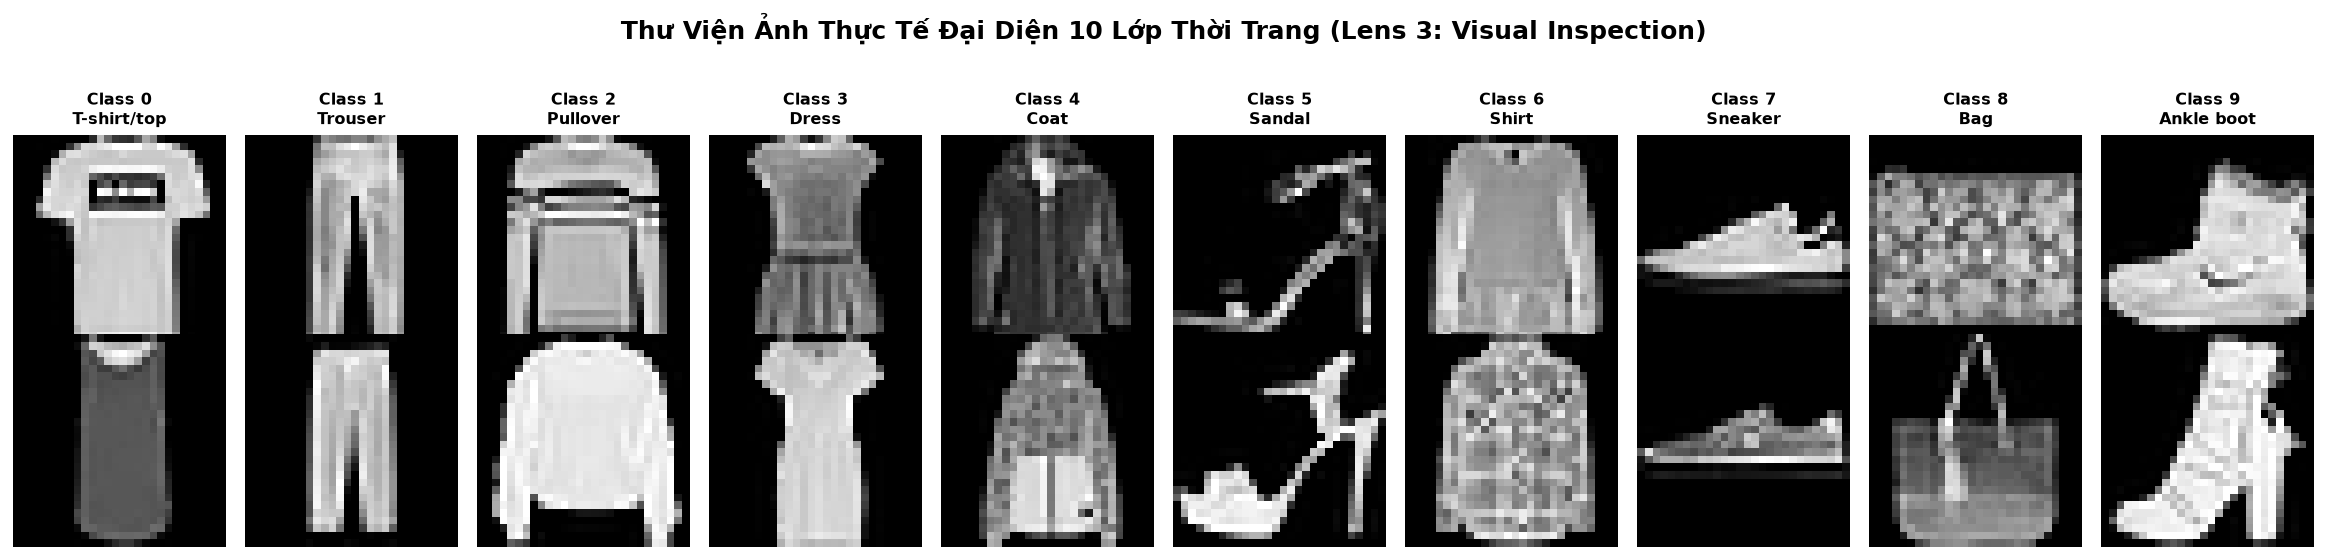

In [8]:
# Hiển thị thư viện ảnh mẫu đại diện 10 lớp
fig_gallery = eda_helpers.plot_gallery(raw_train.data, raw_train.targets, samples_per_class=2)
plt.show()

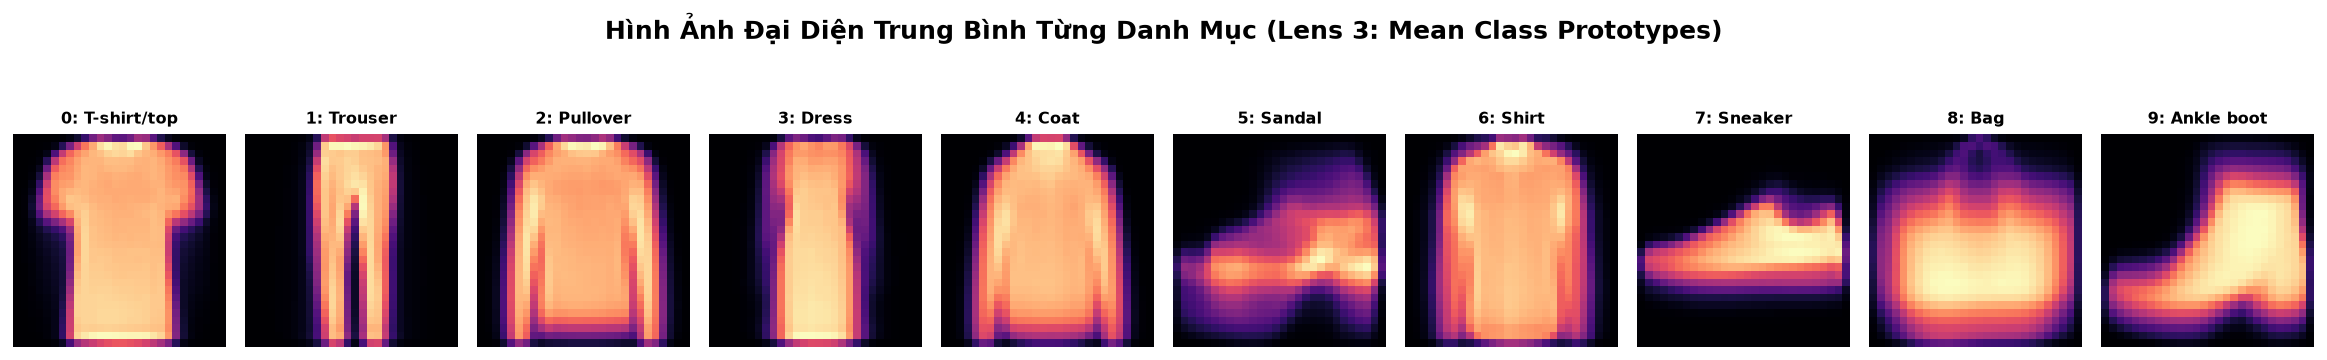

In [9]:
# Tính toán và trực quan hóa ảnh nguyên mẫu trung bình từng lớp
class_prototypes = eda_helpers.compute_class_prototypes(raw_train.data, raw_train.targets)
fig_prototypes = eda_helpers.plot_prototypes_gallery(class_prototypes)
plt.show()

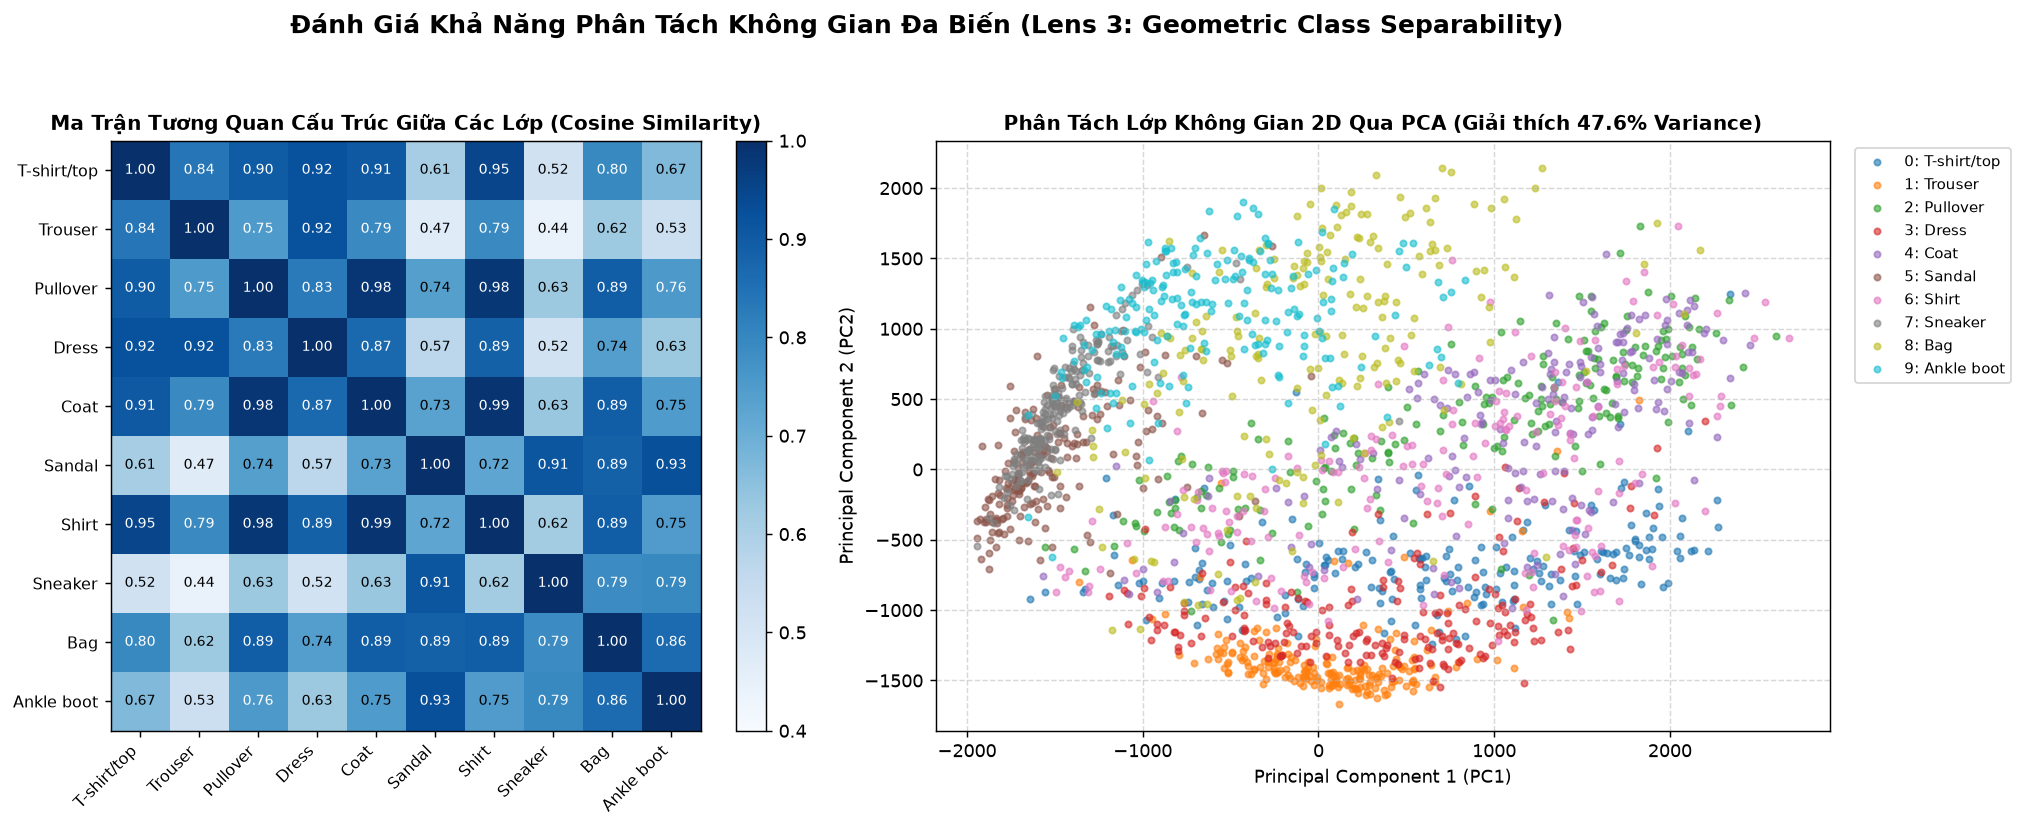

In [10]:
# Lấy mẫu ngẫu nhiên 2.000 điểm ảnh để chiếu giảm chiều PCA phục vụ khảo sát tương tác hình học
sample_size = 2000
sample_images  = raw_train.data[:sample_size]
sample_targets = raw_train.targets[:sample_size]

fig_sim_pca = eda_helpers.plot_interclass_similarity_and_pca(class_prototypes, sample_images, sample_targets)
plt.show()

## 7. Kết Luận Kỹ Thuật & Định Hướng Giai Đoạn Tiếp Theo (Conclusions & Next Steps)

### 7.1. Đúc Kết Từ Khảo Sát Hình Học Dữ Liệu (EDA Findings)
1. **Tính Cân Bằng Tuyệt Đối:** Toàn bộ 10 lớp thời trang đều có đúng 6.000 mẫu (5.500 train, 500 val, 1.000 test), loại trừ hoàn toàn nguy cơ thiên vị lớp (Class Imbalance / Base Rate Fallacy).
2. **Đặc Tính Phân Bố Pixel:** Khoảng $50.8\%$ số điểm ảnh là điểm ảnh nền đen (giá trị bằng 0). Phân bố cường độ bị lệch phải rõ rệt với giá trị trung bình $\mu \approx 0.286$ và độ lệch chuẩn $\sigma \approx 0.353$ (trên thang chuẩn hóa $[0, 1]$).
3. **Tương Quan Không Gian & Ranh Giới Quyết Định:**
   - Nhóm giày dép (*Sandal*, *Sneaker*, *Ankle boot*) và nhóm quần áo dưới (*Trouser*) có hình thái không gian tách biệt rất rõ ràng so với các nhóm khác trên không gian PCA 2D.
   - Nhóm trang phục thân trên (*T-shirt/top*, *Pullover*, *Coat*, *Shirt*) có độ tương quan cấu trúc cosine rất cao ($> 0.85$), tạo ra vùng chồng lấn hình học phức tạp.

### 7.2. Định Hướng Kỹ Thuật Cho Các Bước Tiếp Theo (Decisions for Downstream Modeling)
- **Yêu cầu Chuẩn Hóa:** Cần thiết áp dụng Z-Score Normalization với tham số trung bình $\mu = 0.2860$ và độ lệch chuẩn $\sigma = 0.3530$ để đưa trọng tâm dữ liệu về gốc tọa độ, giúp gradient lan truyền ổn định.
- **Chiến Lược Tăng Cường Dữ Liệu (Augmentation):** Việc lật ngang (`RandomHorizontalFlip`) và dịch nhẹ (`RandomAffine`) là hoàn toàn phù hợp về mặt ngữ nghĩa thời trang để gia tăng tính bất biến hình học.
- **Kỳ Vọng Kiến Trúc:** Mô hình tuyến tính cơ sở (Logistic Regression) và MLP đơn giản sẽ gặp rào cản lớn khi phân tách ranh giới các nhóm trang phục thân trên. Mạng tích chập (CNN) với các bộ lọc không gian cục bộ (Spatial Convolutional Filters) được kỳ vọng sẽ vượt trội đáng kể nhờ khả năng nắm bắt chi tiết vi mô (cổ áo, cúc áo, viền túi).

> **Lưu ý:** Giai đoạn khảo sát hình học dữ liệu (EDA) kết thúc tại đây. Chuỗi triển khai biến đổi dữ liệu (Transforms, Data Augmentation và nạp theo lô đa luồng qua PyTorch DataLoader) sẽ được tiếp nối ở bước xây dựng mô hình huấn luyện.